<a href="https://colab.research.google.com/github/Nyanta432/Dinh_vi_cuon_vi_sai/blob/main/main2(them_calib_huong_RX).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO HỆ THỐNG & FORWARD MODEL ĐỊNH LUẬT BIOT-SAVART CHO CẶP CUỘN THU VI SAI BẤT ĐỐI XỨNG
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.optimize import least_squares
import copy

def rotx(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[1, 0, 0], [0, np.cos(rad), -np.sin(rad)], [0, np.sin(rad),  np.cos(rad)]])

def roty(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[ np.cos(rad), 0, np.sin(rad)], [0, 1, 0], [-np.sin(rad), 0, np.cos(rad)]])

def rotz(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[np.cos(rad), -np.sin(rad), 0], [np.sin(rad),  np.cos(rad), 0], [0, 0, 1]])

def spherical_to_axes(ang6):
    axes = np.zeros((3, 3))
    for j in range(3):
        th, ph = ang6[2*j], ang6[2*j+1]
        axes[j] = [np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)]
    return axes

class SystemConfiguration:
    def __init__(self):
        # Thông số cuộn phát (TX)
        self.Ntx = 195
        self.R = 0.06                               # Bán kính vòng dây TX = 60 mm
        self.I = np.array([1.0, 1.0, 1.0])
        self.f = np.array([5053.0, 6911.0, 5932.0])
        self.M_seg = 72                             # Số đoạn tích phân đường Biot-Savart

        # Ma trận thông số thiết kế của 3 TX (X, Y, Z, Roll, Pitch, Yaw)
        self.TX_positions = np.array([
            [ -0.10044,  0.46278, 0.08352, 15.0,   0.0,   0.0], # TX1
            [ -0.02483,  0.34068, 0.08352,  0.0, -15.0, -30.0], # TX2
            [ -0.16219,  0.33563, 0.08352,  0.0,  15.0,  30.0]  # TX3
        ]).T

        # Thông số 3 cặp cuộn thu vi sai (RX1, RX2, RX3)
        self.Nrx = 100
        self.d_diff_rx = np.array([1.5e-3, 1.6e-3, 1.53e-3])
        self.AK = np.array([np.pi * 4.0, 6.79 * 4.0, 6.0 * 6.87]) * 1e-6
        self.circuit_gain = 1e5
        self.K_theoretical = self.Nrx * self.AK * self.circuit_gain
        self.mu0 = 4 * np.pi * 1e-7

        # Trục alignment ban đầu (X, Z, Y) và tỷ số cân bằng cặp cuộn vi sai beta_rx = [1, 1, 1]
        self.rx_axes = np.array([[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])  # RX1=y, RX2=z, RX3=x
        self.beta_rx = np.array([1.0, 1.0, 1.0])

sys_config = SystemConfiguration()
TX_positions_pre_calib = sys_config.TX_positions.copy()

def _R_batch(poses):
    r, pt, y = np.radians(poses[:, 3]), np.radians(poses[:, 4]), np.radians(poses[:, 5])
    cr, sr, cp, sp, cy, sy = np.cos(r), np.sin(r), np.cos(pt), np.sin(pt), np.cos(y), np.sin(y)
    R = np.zeros((len(poses), 3, 3))
    R[:, 0, 0] = cy*cp; R[:, 0, 1] = cy*sp*sr - sy*cr; R[:, 0, 2] = cy*sp*cr + sy*sr
    R[:, 1, 0] = sy*cp; R[:, 1, 1] = sy*sp*sr + cy*cr; R[:, 1, 2] = sy*sp*cr - cy*sr
    R[:, 2, 0] = -sp;   R[:, 2, 1] = cp*sr;            R[:, 2, 2] = cp*cr
    return R

def B_biot_savart_batch(P, sys, tx_idx):
    c_tx = sys.TX_positions[0:3, tx_idx]
    a, b, g = sys.TX_positions[3:6, tx_idx]
    Rtx = rotz(g) @ roty(b) @ rotx(a)
    phi = np.linspace(0.0, 2.0 * np.pi, sys.M_seg, endpoint=False)
    dphi = 2.0 * np.pi / sys.M_seg
    R = sys.R
    l_loc  = np.column_stack([R * np.cos(phi), R * np.sin(phi), np.zeros_like(phi)])
    dl_loc = np.column_stack([-R * np.sin(phi) * dphi, R * np.cos(phi) * dphi, np.zeros_like(phi)])
    l_world  = c_tx + (l_loc @ Rtx.T)
    dl_world = dl_loc @ Rtx.T
    diff = P[:, None, :] - l_world[None, :, :]
    dist2 = np.sum(diff**2, axis=2)
    dist3 = dist2 * np.sqrt(dist2)
    cross_prod = np.cross(dl_world[None, :, :], diff)
    pref = (sys.mu0 * sys.Ntx * sys.I[tx_idx]) / (4.0 * np.pi)
    return pref * np.sum(cross_prod / dist3[:, :, None], axis=1)

def emf_imperfect_diff_batch(poses, sys, rx_idx, tx_idx):
    # Mô hình Vật lý Thống nhất cho Cặp Cuộn Thu Vi Sai Không Giống Nhau Hoàn Toàn (beta_rx != 1)
    # và Lệch Góc Alignment RX (rx_axes):
    #   EMF_raw = 2*pi*f * | ( B(p + d/2*n) - beta_j * B(p - d/2*n) ) . n |
    n_world = _R_batch(poses) @ sys.rx_axes[rx_idx]
    h = sys.d_diff_rx[rx_idx] / 2.0
    Bp = B_biot_savart_batch(poses[:, 0:3] + h * n_world, sys, tx_idx)
    Bm = B_biot_savart_batch(poses[:, 0:3] - h * n_world, sys, tx_idx)
    beta = sys.beta_rx[rx_idx]
    flux_asym = np.einsum('ij,ij->i', Bp - beta * Bm, n_world)
    return 2.0 * np.pi * sys.f[tx_idx] * np.abs(flux_asym)

print("Đã khởi tạo cấu hình hệ thống & Mô hình Cặp Cuộn Vi Sai Bất Đối Xứng + Biot-Savart thành công.")


Đã khởi tạo cấu hình hệ thống & Mô hình Cặp Cuộn Vi Sai Bất Đối Xứng + Biot-Savart thành công.


In [2]:
# ==============================================================================
# BƯỚC 2: TẢI DỮ LIỆU ĐO THỰC NGHIỆM (conenorot_2_data.csv)
# ==============================================================================
csv_filename = 'conenorot_c_223_data.csv'
data_raw = pd.read_csv(csv_filename, header=None).values
N_REP = 10                                   # 10 lần đo liên tiếp tại mỗi vị trí
data = data_raw.reshape(-1, N_REP, data_raw.shape[1]).mean(axis=1)   # trung bình 10 lần -> 300 mẫu
N_samples = data.shape[0]
emf_measured = data[:, 0:9]

gt_pose = np.zeros((N_samples, 6))
gt_pose[:, 0:3] = data[:, 9:12] / 1000.0
gt_pose_raw_angles = data[:, 12:15].copy()
gt_pose[:, 3:6] = gt_pose_raw_angles   # góc tuyệt đối (không trừ mẫu đầu)
print(f"Đã tải thành công {N_samples} mẫu dữ liệu từ '{csv_filename}'.")


Đã tải thành công 300 mẫu dữ liệu từ 'conenorot_c_223_data.csv'.


In [3]:
# ==============================================================================
# BƯỚC 3: HIỆU CHUẨN ĐỒNG THỜI (CẶP VI SAI BẤT ĐỐI XỨNG BETA_RX + LỆCH GÓC ALIGNMENT RX + TỌA ĐỘ TX) DÙNG BIOT-SAVART
# ==============================================================================
print("Đang chạy Hiệu chuẩn Thống nhất (Imperfect Differential Pair beta_rx + Non-ideal RX Alignment + TX Pose) với Biot-Savart Law...")

# ===== [KHỐI CŨ - đã comment, giữ lại để tham khảo] =====
# # Khởi tạo góc cầu ban đầu từ ma trận xoay khung cảm biến R_cap0
# R_cap0 = np.eye(3)   # góc viên nang đã nằm trong gt_pose
# ang_init = []
# for j in range(3):
#     v = R_cap0 @ sys_config.rx_axes[j]
#     ang_init.extend([np.arccos(np.clip(v[2], -1.0, 1.0)), np.arctan2(v[1], v[0])])
# ang_init = np.array(ang_init)
#
# beta_init = np.array([0.95, 1.00, 0.95])
# DEV_LIM_5 = np.array([0.03, 0.03, 0.03, 3.5, 3.5])
# idx_free = np.array([0, 1, 2, 3, 4])
#
# x0_joint = np.r_[ang_init, beta_init, np.zeros(15)]
# lb_joint = np.r_[ang_init - np.radians(20.0), [0.50, 0.50, 0.50], np.tile(-DEV_LIM_5, 3)]
# ub_joint = np.r_[ang_init + np.radians(20.0), [1.50, 1.50, 1.50], np.tile( DEV_LIM_5, 3)]
# x0_joint = np.clip(x0_joint, lb_joint + 1e-7, ub_joint - 1e-7)
#
# def joint_imperfect_rx_tx_res(x, eps_w=3.0):
#     sys_curr = copy.copy(sys_config)
#     sys_curr.rx_axes = spherical_to_axes(x[0:6])
#     sys_curr.beta_rx = x[6:9].copy()
#     res_all = []
#     for t in range(3):
#         sys_curr.TX_positions = TX_positions_pre_calib.copy()
#         sys_curr.TX_positions[idx_free, t] += x[9 + 5*t : 9 + 5*(t+1)]
#         M = np.column_stack([emf_imperfect_diff_batch(gt_pose, sys_curr, j, t) for j in range(3)])
#         Y = np.column_stack([emf_measured[:, t + 3*j] for j in range(3)])
#         W = 1.0 / (np.abs(Y) + eps_w)
#         K = np.sum((W**2)*M*Y, axis=0) / np.sum((W**2)*(M**2), axis=0)
#         res_all.append((W * (K * M - Y)).ravel())
#     return np.concatenate(res_all)
#
# res_calib = least_squares(
#     joint_imperfect_rx_tx_res, x0_joint, bounds=(lb_joint, ub_joint), method='trf',
#     x_scale=np.r_[[0.1]*6, [0.02]*3, np.tile([0.02, 0.02, 0.02, 3.0, 3.0], 3)], max_nfev=250
# )
#
# ===== [HẾT KHỐI CŨ] =====

# ------------------------------------------------------------------------------
# [MỚI] CALIB HƯỚNG THỰC TẾ CỦA 3 CUỘN RX CÙNG VỚI TX + beta_rx
#   Hướng thiết kế (hệ toàn cục): RX1 = Y, RX2 = Z, RX3 = X. Hướng lắp thật có thể lệch.
#   RX_MODEL = 'rigid': 3 cuộn vuông góc nhau, chung 1 phép xoay dR = Rz(yaw)Ry(pitch)Rx(roll) (3 tham số)
#   RX_MODEL = 'free' : mỗi cuộn 1 hướng độc lập (6 góc cầu, có thể không vuông góc) - cách cũ
#   Vì góc Euler của robot trong file là hằng số (175.82, -0.79, 33.15) nên thử 2 giả thuyết khởi tạo:
#     'B' = RX thẳng hàng Y,Z,X của hệ TOÀN CỤC tại góc ban đầu của robot
#     'A' = RX thẳng hàng Y,Z,X của hệ THÂN robot (rồi mới xoay theo góc ban đầu)
#   Chạy cả hai, lấy nghiệm có cost thấp hơn.
# ------------------------------------------------------------------------------
RX_MODEL     = 'rigid'          # 'rigid' hoặc 'free'
RX_REF_FRAME = 'global'         # 'global': RX thẳng theo trục X,Y,Z của hệ gốc robot (cùng hệ với x,y,z trong file); góc Euler của file chỉ là góc tay robot đã chỉnh để RX thẳng
                                # 'arm'   : RX thẳng theo trục của hệ gắn trên tay robot -> trục thế giới = R(góc file) @ (RX lệch nhỏ)
# [CHẶN CỨNG] cận dưới / cận trên của góc lệch RX so với trục thiết kế, theo từng trục Euler [roll(X), pitch(Y), yaw(Z)] (độ)
RX_LB_DEG    = np.array([-5.0, -5.0, -5.0])
RX_UB_DEG    = np.array([ 5.0,  5.0,  5.0])
BETA_LIM     = 0.10             # [CHẶN beta] beta_rx chỉ được lệch tối đa ±10% so với 1 (2 nửa cuộn gần giống nhau)
RX_PRIOR_SIGMA_DEG = 3.0        # [PHẠT MỀM] độ lệch "dự kiến" (độ); lệch càng xa càng bị phạt bình phương. None = tắt
IDEAL_AXES   = np.array([[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])   # hàng j = trục thiết kế RX_j (Y, Z, X)
RX_NAMES     = ['Y', 'Z', 'X']
R_gt0        = _R_batch(gt_pose[:1])[0]  # xoay (tay robot -> toàn cục) tại tư thế ban đầu (góc Euler trong file)
R_REP        = R_gt0 if RX_REF_FRAME == 'global' else np.eye(3)   # xoay dùng để biểu diễn/so sánh hướng RX với hệ tham chiếu
REF_NAME     = 'toàn cục' if RX_REF_FRAME == 'global' else 'gắn trên tay robot'

def rx_axes_from_x(xa, R_init):
    # Trả về trục RX trong HỆ THÂN robot (n_world = R(pose) @ rx_axes[j])
    if RX_MODEL == 'rigid':
        R_off = R_init @ (rotz(np.degrees(xa[2])) @ roty(np.degrees(xa[1])) @ rotx(np.degrees(xa[0])))
        return (R_off @ IDEAL_AXES.T).T
    return spherical_to_axes(xa)

def make_x0(R_init, e0_deg=(0.0, 0.0, 0.0)):
    if RX_MODEL == 'rigid':
        return np.radians(e0_deg), np.radians(RX_LB_DEG), np.radians(RX_UB_DEG)
    ax0 = (R_init @ IDEAL_AXES.T).T
    a0 = []
    for j in range(3):
        a0.extend([np.arccos(np.clip(ax0[j][2], -1.0, 1.0)), np.arctan2(ax0[j][1], ax0[j][0])])
    a0 = np.array(a0)
    return a0, a0 - np.radians(20.0), a0 + np.radians(20.0)

beta_init = np.array([0.95, 1.00, 0.95])
DEV_LIM_5 = np.array([0.03, 0.03, 0.03, 3.5, 3.5])
idx_free = np.array([0, 1, 2, 3, 4])

def joint_res(x, R_init, na, xa_ref, eps_w=3.0):
    sys_curr = copy.copy(sys_config)
    sys_curr.rx_axes = rx_axes_from_x(x[0:na], R_init)
    sys_curr.beta_rx = x[na:na+3].copy()
    res_all = []
    for t in range(3):
        sys_curr.TX_positions = TX_positions_pre_calib.copy()
        sys_curr.TX_positions[idx_free, t] += x[na+3 + 5*t : na+3 + 5*(t+1)]
        M = np.column_stack([emf_imperfect_diff_batch(gt_pose, sys_curr, j, t) for j in range(3)])
        Y = np.column_stack([emf_measured[:, t + 3*j] for j in range(3)])
        W = 1.0 / (np.abs(Y) + eps_w)
        K = np.sum((W**2)*M*Y, axis=0) / np.sum((W**2)*(M**2), axis=0)
        res_all.append((W * (K * M - Y)).ravel())
    if RX_PRIOR_SIGMA_DEG is not None:      # phạt mềm: (góc - góc khởi tạo) / sigma  (tương đương prior Gauss lên góc lệch)
        res_all.append((x[0:na] - xa_ref) / np.radians(RX_PRIOR_SIGMA_DEG))
    return np.concatenate(res_all)

def rx_world_euler(axes_body):
    # Euler (roll quanh X, pitch quanh Y, yaw quanh Z; Rz.Ry.Rx) của bộ 3 cuộn RX so với bộ trục thiết kế (Y,Z,X) trong hệ toàn cục
    n0_ = (R_REP @ axes_body.T).T
    S_ = np.array([1.0 if np.dot(n0_[j], IDEAL_AXES[j]) >= 0 else -1.0 for j in range(3)])
    Rt_ = (n0_ * S_[:, None]).T
    U_, _, Vt_ = np.linalg.svd(Rt_); Rd_ = (U_ @ Vt_) @ IDEAL_AXES
    return np.array([np.degrees(np.arctan2(Rd_[2, 1], Rd_[2, 2])), np.degrees(-np.arcsin(np.clip(Rd_[2, 0], -1, 1))), np.degrees(np.arctan2(Rd_[1, 0], Rd_[0, 0]))])

# (R_init, Euler khởi tạo [độ]): nhiều điểm khởi tạo để xem hướng RX có xác định chắc chắn hay không
starts = {   # Bạn đặt RX bằng mắt thẳng theo trục toàn cục -> chỉ dùng giả thuyết 'RX thẳng trục toàn cục'
    'RX thẳng trục hệ ' + REF_NAME : (R_REP.T, (0.0, 0.0, 0.0)),
}
fits = {}
print("   Các điểm khởi tạo và hướng RX tìm được (Euler lệch so với hệ tham chiếu [roll X, pitch Y, yaw Z]):")
for name, (R_init, e0) in starts.items():
    xa0, xa_lb, xa_ub = make_x0(R_init, e0); na = len(xa0)
    x0 = np.r_[xa0, beta_init, np.zeros(15)]
    lb = np.r_[xa_lb, [1.0 - BETA_LIM]*3, np.tile(-DEV_LIM_5, 3)]
    ub = np.r_[xa_ub, [1.0 + BETA_LIM]*3, np.tile( DEV_LIM_5, 3)]
    x0 = np.clip(x0, lb + 1e-7, ub - 1e-7)
    xs = np.r_[[0.1]*na, [0.02]*3, np.tile([0.02, 0.02, 0.02, 3.0, 3.0], 3)]
    r = least_squares(joint_res, x0, bounds=(lb, ub), method='trf', x_scale=xs, max_nfev=250, args=(R_init, na, xa0))
    fits[name] = (r, R_init, na)
    eul_s = rx_world_euler(rx_axes_from_x(r.x[:na], R_init))
    print(f"   - {name}: cost = {r.cost:.3f} | Euler = ({eul_s[0]:+.1f}°, {eul_s[1]:+.1f}°, {eul_s[2]:+.1f}°) | beta = {np.round(r.x[na:na+3], 3)}")
best_name = min(fits, key=lambda k: fits[k][0].cost)
res_calib, R_init_best, NA = fits[best_name]
if RX_MODEL != 'rigid': print('   (mode free: Euler là của bộ 3 trục sau khi làm vuông góc)')
print(f"   => Chọn giả thuyết khởi tạo: {best_name}")

# Cập nhật thông số tối ưu vào sys_config
sys_config.rx_axes = rx_axes_from_x(res_calib.x[0:NA], R_init_best)   # trục RX trong hệ thân (Section 4 dùng lại)
sys_config.beta_rx = res_calib.x[NA:NA+3].copy()
sys_config.TX_positions = TX_positions_pre_calib.copy()
calibrated_K_matrix = np.zeros((3, 3))
emf_pred_post = np.zeros_like(emf_measured)

for t in range(3):
    sys_config.TX_positions[idx_free, t] += res_calib.x[NA+3 + 5*t : NA+3 + 5*(t+1)]
    M = np.column_stack([emf_imperfect_diff_batch(gt_pose, sys_config, j, t) for j in range(3)])
    Y = np.column_stack([emf_measured[:, t + 3*j] for j in range(3)])
    W = 1.0 / (np.abs(Y) + 3.0)
    calibrated_K_matrix[:, t] = np.sum((W**2)*M*Y, axis=0) / np.sum((W**2)*(M**2), axis=0)
    for j in range(3):
        emf_pred_post[:, t + 3*j] = calibrated_K_matrix[j, t] * M[:, j]

W1 = 1.0 / (np.abs(emf_measured) + 1.0)
J_w1_post = 0.5 * np.sum((W1 * (emf_pred_post - emf_measured))**2)
r2_9   = [1.0 - np.sum((emf_measured[:,c]-emf_pred_post[:,c])**2)/np.sum((emf_measured[:,c]-np.mean(emf_measured[:,c]))**2) for c in range(9)]
r_9    = [np.corrcoef(emf_measured[:,c], emf_pred_post[:,c])[0,1] for c in range(9)]
mae_9  = [np.mean(np.abs(emf_measured[:,c]-emf_pred_post[:,c])) for c in range(9)]
nrmse_9 = [np.sqrt(np.mean((emf_measured[:,c]-emf_pred_post[:,c])**2))/(np.max(emf_measured[:,c])-np.min(emf_measured[:,c]))*100 for c in range(9)]

print("\n=========================================================================================================")
print("🎯 KẾT QUẢ HIỆU CHUẨN CẶP CUỘN THU VI SAI BẤT ĐỐI XỨNG (BETA_RX) & GÓC ALIGNMENT RX TRÊN DỮ LIỆU THỰC")
print("=========================================================================================================")
print("1️⃣ Tỷ số cân bằng giữa 2 nửa cuộn trong cặp cuộn vi sai beta_j = (N_j^- A_j^-) / (N_j^+ A_j^+):")
for j in range(3):
    mismatch = (1.0 - sys_config.beta_rx[j]) * 100.0
    print(f"   - Cặp cuộn RX{j+1}: beta_{j+1} = {sys_config.beta_rx[j]:.5f}  (Độ lệch bất đối xứng giữa 2 nửa cuộn = {mismatch:+.3f}%)")

print("\n2️⃣ Hướng THỰC TẾ của 3 cuộn RX so với hệ toạ độ {REF_NAME} (X, Y, Z), tại tư thế ban đầu của robot:")
n0 = (R_REP @ sys_config.rx_axes.T).T                    # trục mỗi cuộn trong hệ toàn cục
glob = np.eye(3)
for j in range(3):
    n = n0[j] * (1.0 if np.dot(n0[j], IDEAL_AXES[j]) >= 0 else -1.0)   # mô hình chẵn theo n: chọn chiều gần trục thiết kế
    ang_xyz = np.degrees(np.arccos(np.clip(np.abs(n), 0, 1)))          # góc tới trục X, Y, Z
    tilt = np.degrees(np.arccos(np.clip(np.dot(n, IDEAL_AXES[j]), -1.0, 1.0)))
    az = np.degrees(np.arctan2(n[1], n[0])); el = np.degrees(np.arcsin(np.clip(n[2], -1, 1)))
    print(f"   - RX{j+1} (thiết kế trục {RX_NAMES[j]}): n = {np.round(n, 4)} | góc tới X/Y/Z = ({ang_xyz[0]:.2f}°, {ang_xyz[1]:.2f}°, {ang_xyz[2]:.2f}°) | LỆCH so với trục {RX_NAMES[j]} = {tilt:.2f}° | azimuth = {az:.2f}°, elevation = {el:.2f}°")

# Euler của cả bộ 3 cuộn so với bộ trục thiết kế (Y,Z,X) trong hệ toàn cục: R_dev = R_triad @ E^T, quy ước Rz(yaw)Ry(pitch)Rx(roll)
S = np.array([1.0 if np.dot(n0[j], IDEAL_AXES[j]) >= 0 else -1.0 for j in range(3)])
R_triad = (n0 * S[:, None]).T                              # cột j = trục RX_j (hệ toàn cục)
U_, _, Vt_ = np.linalg.svd(R_triad); R_triad = U_ @ Vt_    # làm vuông góc hoàn toàn (nếu mode 'free')
R_dev = R_triad @ IDEAL_AXES                               # IDEAL_AXES = E^T (hàng j = trục j)
eul_pitch = np.degrees(-np.arcsin(np.clip(R_dev[2, 0], -1, 1)))
eul_roll  = np.degrees(np.arctan2(R_dev[2, 1], R_dev[2, 2]))
eul_yaw   = np.degrees(np.arctan2(R_dev[1, 0], R_dev[0, 0]))
print(f"   - GÓC EULER THỰC TẾ của bộ RX so với hệ {REF_NAME} (0,0,0 = RX thẳng đúng Y,Z,X): roll(X) = {eul_roll:+.2f}°, pitch(Y) = {eul_pitch:+.2f}°, yaw(Z) = {eul_yaw:+.2f}°")
if RX_MODEL == 'rigid':
    dRd = np.degrees(res_calib.x[0:3])
    hit = ['chạm biên' if (abs(dRd[k]-RX_LB_DEG[k]) < 0.05 or abs(dRd[k]-RX_UB_DEG[k]) < 0.05) else 'trong biên' for k in range(3)]
    print(f"   - Góc lệch RX (roll, pitch, yaw) = ({dRd[0]:+.2f}°, {dRd[1]:+.2f}°, {dRd[2]:+.2f}°) | cận dưới = {RX_LB_DEG} | cận trên = {RX_UB_DEG} | {hit}")
print(f"   - Mức vuông góc giữa các cuộn: ∠(RX1,RX2) = {np.degrees(np.arccos(abs(np.dot(sys_config.rx_axes[0], sys_config.rx_axes[1])))):.2f}°, ∠(RX1,RX3) = {np.degrees(np.arccos(abs(np.dot(sys_config.rx_axes[0], sys_config.rx_axes[2])))):.2f}°, ∠(RX2,RX3) = {np.degrees(np.arccos(abs(np.dot(sys_config.rx_axes[1], sys_config.rx_axes[2])))):.2f}°")
print(f"   - Góc Euler robot trong file (ban đầu): roll = {gt_pose[0,3]:.2f}°, pitch = {gt_pose[0,4]:.2f}°, yaw = {gt_pose[0,5]:.2f}°")

print("\n3️⃣ Tọa độ 3 cuộn phát TX sau hiệu chuẩn:")
for t in range(3):
    p_pre  = TX_positions_pre_calib[:, t]
    p_post = sys_config.TX_positions[:, t]
    d_pos  = (p_post[0:3] - p_pre[0:3]) * 1000.0
    print(f"   - TX{t+1}: Pos = ({p_post[0]*1000:.2f}, {p_post[1]*1000:.2f}, {p_post[2]*1000:.2f}) mm | ΔPos = ({d_pos[0]:+.2f}, {d_pos[1]:+.2f}, {d_pos[2]:+.2f}) mm | Euler = ({p_post[3]:.2f}°, {p_post[4]:.2f}°, {p_post[5]:.2f}°)")

print("\n4️⃣ Chỉ số Định lượng Khớp 9 Kênh EMF (Back-test Forward Signal Metrics):")
print(f"   - Weighted Cost J_W1 = {J_w1_post:.2f} ")
print(f"   - Mean EMF MAE       = {np.mean(mae_9):.4f} V")
print(f"   - Mean EMF NRMSE     = {np.mean(nrmse_9):.2f}%")
print(f"   - Mean Pearson r     = {np.mean(r_9):.4f} (Min r = {np.min(r_9):.4f})")
print(f"   - Mean R²            = {np.mean(r2_9):.4f} (Min R² = {np.min(r2_9):.4f})")
for j in range(3):
    print(f"     + RX{j+1} (beta={sys_config.beta_rx[j]:.4f}): " + " | ".join([f"TX{t+1}: MAE={mae_9[t+3*j]:.3f}V, r={r_9[t+3*j]:.3f}, R²={r2_9[t+3*j]:.3f}" for t in range(3)]))


Đang chạy Hiệu chuẩn Thống nhất (Imperfect Differential Pair beta_rx + Non-ideal RX Alignment + TX Pose) với Biot-Savart Law...
   Các điểm khởi tạo và hướng RX tìm được (Euler lệch so với hệ tham chiếu [roll X, pitch Y, yaw Z]):
   - RX thẳng trục hệ toàn cục: cost = 15.669 | Euler = (-0.7°, -1.1°, -0.1°) | beta = [0.9 1.1 0.9]
   => Chọn giả thuyết khởi tạo: RX thẳng trục hệ toàn cục

🎯 KẾT QUẢ HIỆU CHUẨN CẶP CUỘN THU VI SAI BẤT ĐỐI XỨNG (BETA_RX) & GÓC ALIGNMENT RX TRÊN DỮ LIỆU THỰC
1️⃣ Tỷ số cân bằng giữa 2 nửa cuộn trong cặp cuộn vi sai beta_j = (N_j^- A_j^-) / (N_j^+ A_j^+):
   - Cặp cuộn RX1: beta_1 = 0.90000  (Độ lệch bất đối xứng giữa 2 nửa cuộn = +10.000%)
   - Cặp cuộn RX2: beta_2 = 1.10000  (Độ lệch bất đối xứng giữa 2 nửa cuộn = -10.000%)
   - Cặp cuộn RX3: beta_3 = 0.90000  (Độ lệch bất đối xứng giữa 2 nửa cuộn = +10.000%)

2️⃣ Hướng THỰC TẾ của 3 cuộn RX so với hệ toạ độ {REF_NAME} (X, Y, Z), tại tư thế ban đầu của robot:
   - RX1 (thiết kế trục Y): n = [ 0.0016  0.9999 

Section 4 dùng RX_MODEL = 'rigid', RX_REF_FRAME = 'global' | Euler RX so với hệ toàn cục = (roll -0.73°, pitch -1.11°, yaw -0.08°) | beta_rx = [0.9 1.1 0.9]
📍 KẾT QUẢ ĐỊNH VỊ NGƯỢC 6-DOF TRÊN DỮ LIỆU THỰC (BIOT-SAVART + IMPERFECT DIFF RX + ALIGNMENT)
  - 3D Position RMSE   : 31.89 mm
  - 3D Position MAE    : 27.02 mm
  - 3D Position Median : 23.87 mm
  - Sai số góc (độ) so với góc Euler của file: RMSE roll = 7.31° | pitch = 7.68° | yaw = 5.65°
  - Sai số theo từng trục: RMSE_X = 16.81 mm | RMSE_Y = 23.91 mm | RMSE_Z = 12.76 mm


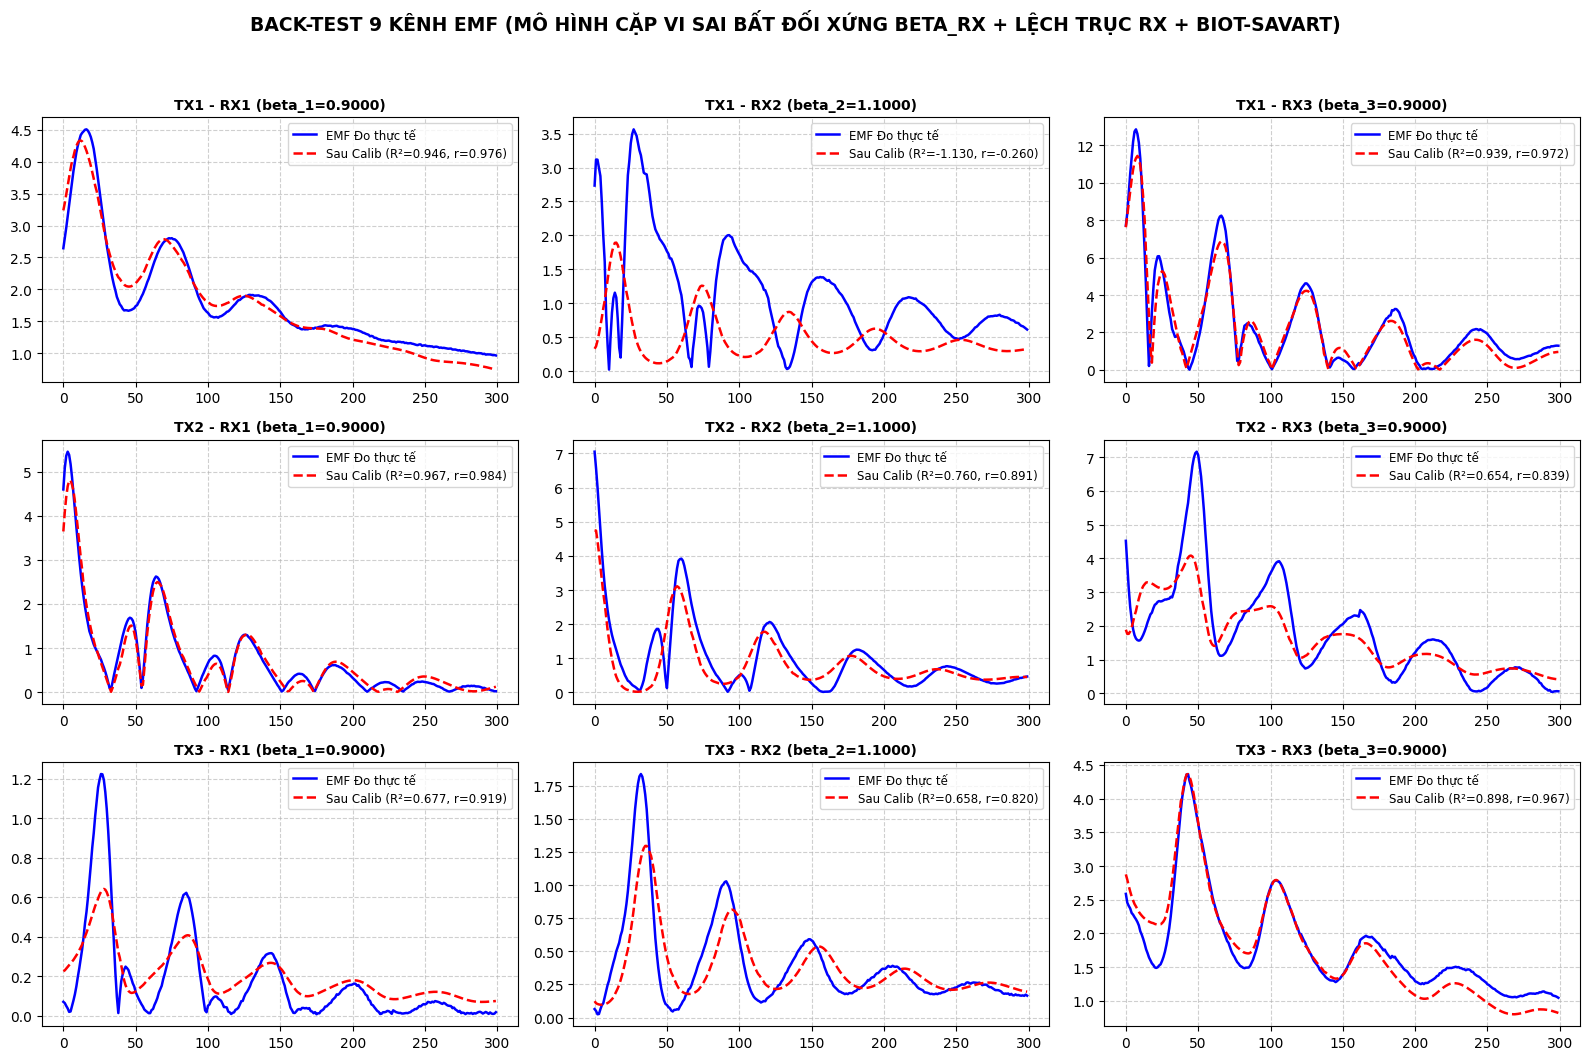

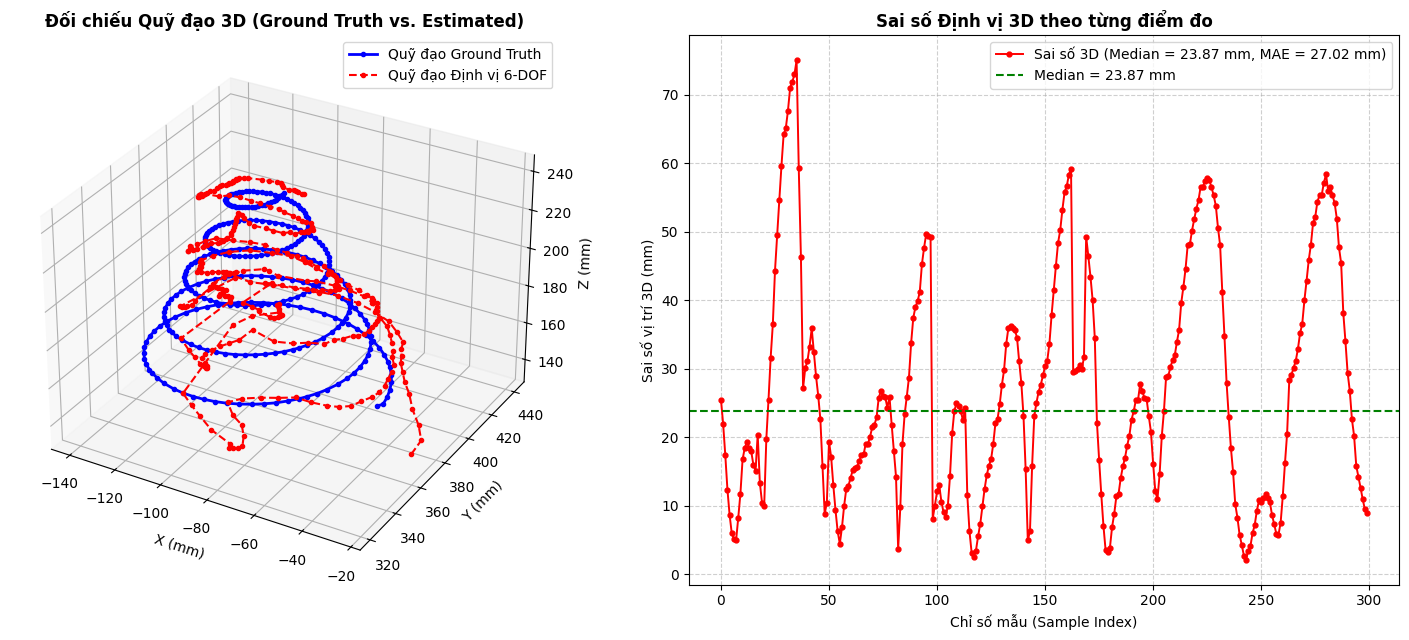

In [4]:
# ==============================================================================
# BƯỚC 4: BACK-TEST ĐỊNH VỊ NGƯỢC 6-DOF & VẼ ĐỒ THỊ 9 KÊNH EMF + QUỸ ĐẠO 3D
# ==============================================================================
# [MỚI] Section 4 chạy theo Section 3 mới: dùng trục RX thực tế đã calib (sys_config.rx_axes), beta_rx, K và pose TX đã calib
assert 'RX_MODEL' in globals(), "Hãy chạy Section 3 (bản mới) trước Section 4"
print(f"Section 4 dùng RX_MODEL = '{RX_MODEL}', RX_REF_FRAME = '{RX_REF_FRAME}' | Euler RX so với hệ {REF_NAME} = (roll {eul_roll:+.2f}°, pitch {eul_pitch:+.2f}°, yaw {eul_yaw:+.2f}°) | beta_rx = {np.round(sys_config.beta_rx, 4)}")

min_traj = np.min(gt_pose, axis=0)
max_traj = np.max(gt_pose, axis=0)
lb_inv = np.concatenate([min_traj[0:3] - 0.1, min_traj[3:6] - 10.0])
ub_inv = np.concatenate([max_traj[0:3] + 0.1, max_traj[3:6] + 10.0])

estimated_pose = np.zeros_like(gt_pose)
for i in range(N_samples):
    p0 = gt_pose[i].copy()
    p0[0:3] += 0.0001
    def res_inv(pose):
        p2 = pose[None, :]
        r_out = np.zeros(9)
        for rx_j in range(3):
            for tx_i in range(3):
                val = emf_imperfect_diff_batch(p2, sys_config, rx_j, tx_i)[0]
                r_out[tx_i + 3*rx_j] = calibrated_K_matrix[rx_j, tx_i] * val - emf_measured[i, tx_i + 3*rx_j]
        return r_out
    r = least_squares(res_inv, p0, bounds=(lb_inv, ub_inv), method='trf', x_scale='jac', ftol=1e-8, xtol=1e-8, gtol=1e-8)
    estimated_pose[i] = r.x

err_3d = np.linalg.norm(estimated_pose[:, 0:3] - gt_pose[:, 0:3], axis=1) * 1000.0
rmse_xyz = np.sqrt(np.mean((estimated_pose[:, 0:3] - gt_pose[:, 0:3])**2, axis=0)) * 1000.0

print("=========================================================================================================")
print("📍 KẾT QUẢ ĐỊNH VỊ NGƯỢC 6-DOF TRÊN DỮ LIỆU THỰC (BIOT-SAVART + IMPERFECT DIFF RX + ALIGNMENT)")
print("=========================================================================================================")
print(f"  - 3D Position RMSE   : {np.sqrt(np.mean(err_3d**2)):.2f} mm")
print(f"  - 3D Position MAE    : {np.mean(err_3d):.2f} mm")
print(f"  - 3D Position Median : {np.median(err_3d):.2f} mm")
err_ang = np.sqrt(np.mean((estimated_pose[:, 3:6] - gt_pose[:, 3:6])**2, axis=0))
print(f"  - Sai số góc (độ) so với góc Euler của file: RMSE roll = {err_ang[0]:.2f}° | pitch = {err_ang[1]:.2f}° | yaw = {err_ang[2]:.2f}°")
print(f"  - Sai số theo từng trục: RMSE_X = {rmse_xyz[0]:.2f} mm | RMSE_Y = {rmse_xyz[1]:.2f} mm | RMSE_Z = {rmse_xyz[2]:.2f} mm")

# Vẽ đồ thị 9 kênh EMF
fig1, axs = plt.subplots(3, 3, figsize=(16, 11))
fig1.suptitle('BACK-TEST 9 KÊNH EMF (MÔ HÌNH CẶP VI SAI BẤT ĐỐI XỨNG BETA_RX + LỆCH TRỤC RX + BIOT-SAVART)', fontsize=13.5, fontweight='bold')
for rx in range(3):
    for tx in range(3):
        idx = tx + 3 * rx
        ax = axs[tx, rx]
        ax.plot(emf_measured[:, idx], 'b-', linewidth=1.8, label='EMF Đo thực tế')
        ax.plot(emf_pred_post[:, idx], 'r--', linewidth=1.8, label=f'Sau Calib (R²={r2_9[idx]:.3f}, r={r_9[idx]:.3f})')
        ax.set_title(f'TX{tx+1} - RX{rx+1} (beta_{rx+1}={sys_config.beta_rx[rx]:.4f})', fontsize=10, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='best', fontsize=8.5)
plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()

# Vẽ đồ thị Quỹ đạo 3D và Sai số định vị
fig2 = plt.figure(figsize=(15, 6.5))
ax3d = fig2.add_subplot(121, projection='3d')
ax3d.plot(gt_pose[:,0]*1000, gt_pose[:,1]*1000, gt_pose[:,2]*1000, 'b.-', linewidth=2, label='Quỹ đạo Ground Truth')
ax3d.plot(estimated_pose[:,0]*1000, estimated_pose[:,1]*1000, estimated_pose[:,2]*1000, 'r.--', linewidth=1.5, label='Quỹ đạo Định vị 6-DOF')
ax3d.set_xlabel('X (mm)'); ax3d.set_ylabel('Y (mm)'); ax3d.set_zlabel('Z (mm)')
ax3d.set_title('Đối chiếu Quỹ đạo 3D (Ground Truth vs. Estimated)', fontweight='bold')
ax3d.legend()

ax_err = fig2.add_subplot(122)
ax_err.plot(err_3d, 'r-o', markersize=3.5, linewidth=1.4, label=f'Sai số 3D (Median = {np.median(err_3d):.2f} mm, MAE = {np.mean(err_3d):.2f} mm)')
ax_err.axhline(np.median(err_3d), color='g', linestyle='--', label=f'Median = {np.median(err_3d):.2f} mm')
ax_err.set_xlabel('Chỉ số mẫu (Sample Index)'); ax_err.set_ylabel('Sai số vị trí 3D (mm)')
ax_err.set_title('Sai số Định vị 3D theo từng điểm đo', fontweight='bold')
ax_err.grid(True, linestyle='--', alpha=0.6)
ax_err.legend()
plt.tight_layout()
plt.show()
